# NeuroMotor - Wrist Dataset

In [1]:
%cd ..

/home/willraftery/PhD/projects/github/emg-stream


In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("data/neuromotor_wrist")

h5_files = list(data_dir.glob("*.hdf5"))
print(f"Found {len(h5_files)} HDF5 files in {data_dir}")

Found 6 HDF5 files in data/neuromotor_wrist


In [3]:
example_file = h5_files[0]
import pandas as pd

print(example_file)

with h5py.File(example_file, 'r') as f:
    print("Keys in the HDF5 file:", list(f.keys()))

    data = f['data']
    print("Data shape:", data.shape)
    print("Data dtype:", data.dtype)
    print("Data keys:", list(data.attrs.keys()))
    print("Data attributes:", {key: data.attrs[key] for key in data.attrs.keys()})

    time = data['time']
    print("Start Time:", time[0])
    print("End Time:", time[-1])
    print("Duration:", time[-1] - time[0])


    stages = pd.read_hdf(example_file, "stages")
    print(stages.head())

    emg = data['emg']
    print("EMG shape:", emg.shape)



data/neuromotor_wrist/wrist_user_002_dataset_000.hdf5
Keys in the HDF5 file: ['data', 'stages']
Data shape: (3290112,)
Data dtype: [('emg', '<f4', (16,)), ('time', '<f8'), ('wrist_angles', '<f8', (2,))]
Data keys: ['task']
Data attributes: {'task': 'wrist'}
Start Time: 1713965756.2016091
End Time: 1713967401.2215176
Duration: 1645.0199084281921
          start           end                            name
0  1.713966e+09  1.713966e+09                  open_loop_task
1  1.713966e+09  1.713966e+09        hold_neutral_wrist_angle
2  1.713966e+09  1.713966e+09         clockwise_wrist_circles
3  1.713966e+09  1.713966e+09  counterclockwise_wrist_circles
4  1.713966e+09  1.713966e+09         flexions_and_extensions
EMG shape: (3290112, 16)


In [4]:

def load_corpus(dataset_dir: Path) -> pd.DataFrame:
    """Load the corpus CSV defining train/val/test segments."""
    corpus_path = dataset_dir / "wrist_corpus.csv"
    if not corpus_path.exists():
        raise FileNotFoundError(f"Corpus CSV not found at {corpus_path}")
    df = pd.read_csv(corpus_path)
    # Normalise split names to match our convention
    df['split'] = df['split'].str.lower().str.strip()
    return df


def timestamps_to_indices(timestamps: np.ndarray, start_time: float,
                           end_time: float) -> tuple:
    """
    Convert absolute timestamps to array indices.

    Args:
        timestamps: (T,) array of absolute timestamps
        start_time: segment start timestamp
        end_time:   segment end timestamp

    Returns:
        (start_idx, end_idx)
    """
    start_idx = np.searchsorted(timestamps, start_time, side='left')
    end_idx   = np.searchsorted(timestamps, end_time,   side='right')
    return int(start_idx), int(end_idx)

In [ ]:
# Open up the corpus CSV to see what kind of data split we have
corpus_df = load_corpus(data_dir)
print(corpus_df.head())

# Get stats. Is the split inter-subject or intra-subject? How many subjects? How many runs per subject?
num_subjects = corpus_df['user_number'].nunique()
print(f"Number of subjects: {num_subjects}")

# Get number of train/val/test runs
split_counts = corpus_df['split'].value_counts()
print("Split counts:")
print(split_counts)

# As percentage
split_percentages = corpus_df['split'].value_counts(normalize=True) * 100
print("Split percentages:")
print(split_percentages)

# Check if the split is inter-subject or intra-subject
# If each subject appears in only one split, it's inter-subject. Otherwise, it's intra-subject.
subject_split_counts = corpus_df.groupby('user_number')['split'].nunique()
print(subject_split_counts)
# Print which splits each subject appears in
print(corpus_df.groupby('user_number')['split'].unique())
if (subject_split_counts > 1).any():
    print("The split is intra-subject (some subjects appear in multiple splits).")
else:
    print("The split is inter-subject (each subject appears in only one split).")



          start           end  split  dataset_number  user_number  \
0  1.712073e+09  1.712073e+09  train               0           95   
1  1.712074e+09  1.712074e+09  train               0           95   
2  1.712074e+09  1.712074e+09  train               0           95   
3  1.712074e+09  1.712074e+09  train               0           95   
4  1.712074e+09  1.712074e+09  train               0           95   

                           dataset  
0  wrist_user_095_dataset_000.hdf5  
1  wrist_user_095_dataset_000.hdf5  
2  wrist_user_095_dataset_000.hdf5  
3  wrist_user_095_dataset_000.hdf5  
4  wrist_user_095_dataset_000.hdf5  
Number of subjects: 100
Split counts:
split
train    2614
val       372
test      364
Name: count, dtype: int64
Split percentages:
split
train    78.029851
val      11.104478
test     10.865672
Name: proportion, dtype: float64
user_number
0     1
1     1
2     1
3     1
4     1
     ..
95    1
96    1
97    1
98    1
99    1
Name: split, Length: 100, dtype: int

In [ ]:
corpus_by_file = load_corpus(data_dir)

# Quick diagnostic — run on one file before full conversion
with h5py.File(h5_files[0], 'r') as src:
    timestamps = np.array(src['data']['time'])
    stages     = pd.read_hdf(h5_files[0], "stages")

fname          = h5_files[0].name
file_segments  = corpus_by_file.get_group(fname)

for _, seg in file_segments.iterrows():
    stage_id, stage_name = get_stage_label(seg["start"], seg["end"], stages)
    duration = seg["end"] - seg["start"]
    print(f"  seg [{seg['start']:.1f} → {seg['end']:.1f}] "
          f"({duration:.1f}s) → stage: {stage_name} (id={stage_id})")

NameError: name 'corpus_by_file' is not defined

In [2]:
%cd ..

/home/willraftery/PhD/projects/github/emg-stream


Pass 1: Computing training set statistics


Train runs: 2388it [00:20, 118.35it/s]



Pass 2: Evaluating mean-prediction baseline on test set


Test runs: 675it [00:03, 185.12it/s]



════════════════════════════════════════════════════════════
  NEUROMOTOR-WRIST — JOINT ANGLE AUDIT SUMMARY
════════════════════════════════════════════════════════════

Dataset Overview
────────────────────────────────────────────────────────────
  Training runs          : 2388
  Test runs              : 675
  Total training samples : 187,172,464
  Training windows (1s)  : 934,742
  Run length — mean      : 78380.4 samples  (391.90s)
  Run length — min       : 23464 samples  (117.32s)
  Run length — max       : 347896 samples  (1739.48s)
  Run length — std       : 68248.5 samples

Joint Angle Statistics (training set, sample-level)
────────────────────────────────────────────────────────────
  Joint         Min      Max     Mean      Std    Range
  ──────── ──────── ──────── ──────── ──────── ────────
  0          -1.606    1.487    0.260    0.287    3.093
  1          -1.209    1.559   -0.251    0.221    2.768
  ──────── ──────── ──────── ──────── ──────── ────────
  Mean       -1.4

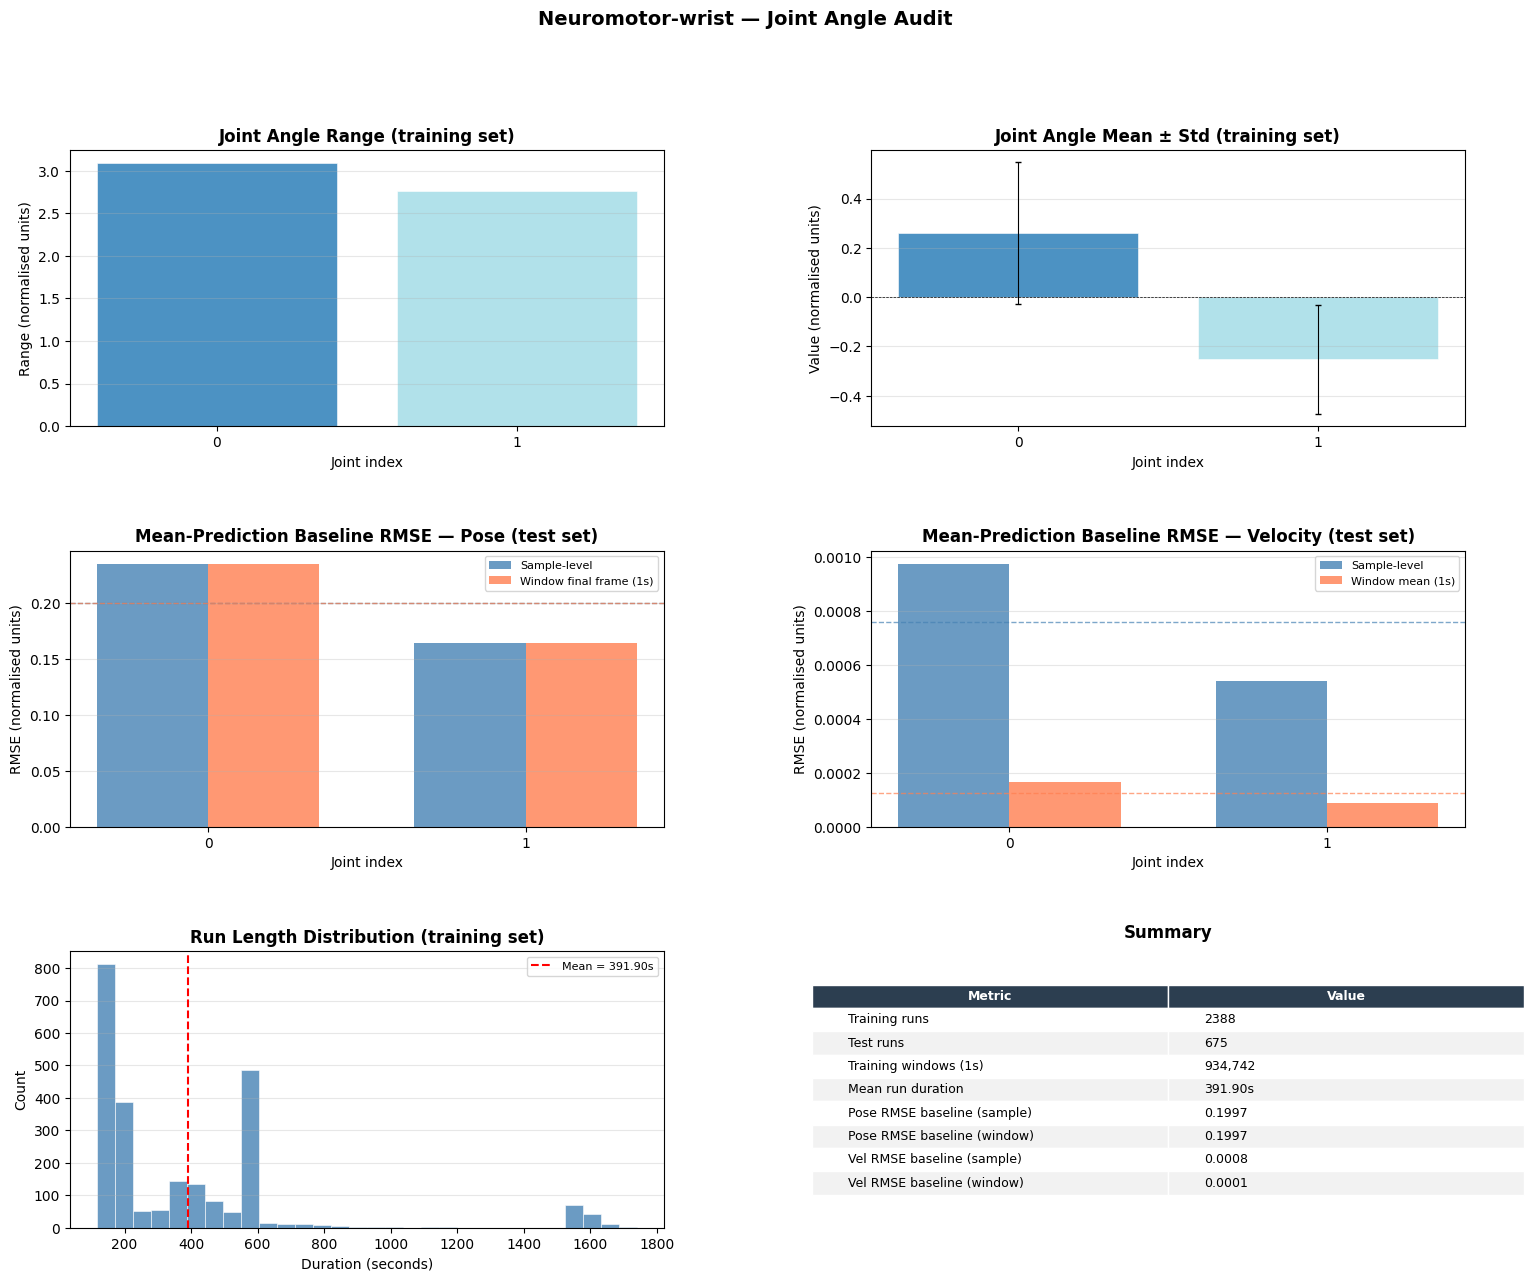


Figure saved to figures/neuromotor_wrist_jntang_audit.pdf


In [3]:
import h5py
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

# ------------------------------------------------------------------ #
# Config
# ------------------------------------------------------------------ #

HDF5_PATH     = Path("data/neuromotor_wrist/neuromotor_wrist.hdf5")
N_JOINTS      = 2
WINDOW_SIZE   = 200   # samples at 200Hz = 1s
TRAIN_SPLIT   = "train"
TEST_SPLIT    = "test"

# ------------------------------------------------------------------ #
# Helpers
# ------------------------------------------------------------------ #

def iter_runs(root, split):
    """Yield (run_group, subject_meta) for all runs matching split."""
    for subj_id in root.keys():
        subj_group = root[subj_id]
        subj_meta  = dict(subj_group.attrs)
        if subj_meta.get("inter_subject_split", "None") != split:
            continue
        for sess_id in subj_group.keys():
            if not isinstance(subj_group[sess_id], h5py.Group):
                continue
            sess_group = subj_group[sess_id]
            for run_key in sess_group.keys():
                if not isinstance(sess_group[run_key], h5py.Group):
                    continue
                yield sess_group[run_key], subj_meta


def windowed_final_pose(jntang, window_size):
    """
    Extract the final pose of each non-overlapping window.
    Returns array of shape (n_windows, N_JOINTS).
    """
    n_windows = len(jntang) // window_size
    if n_windows == 0:
        return None
    truncated = jntang[:n_windows * window_size]           # (n_windows*W, J)
    windows   = truncated.reshape(n_windows, window_size, N_JOINTS)
    return windows[:, -1, :]                               # (n_windows, J)


def windowed_mean_velocity(jntang, window_size):
    """
    Compute mean finite-difference velocity within each non-overlapping window.
    Returns array of shape (n_windows, N_JOINTS).
    """
    n_windows = len(jntang) // window_size
    if n_windows == 0:
        return None
    truncated  = jntang[:n_windows * window_size]
    windows    = truncated.reshape(n_windows, window_size, N_JOINTS)
    velocities = np.diff(windows, axis=1)                  # (n_windows, W-1, J)
    return velocities.mean(axis=1)                         # (n_windows, J)


def rmse(pred, target, axis=0):
    return np.sqrt(np.mean((pred - target) ** 2, axis=axis))


# ------------------------------------------------------------------ #
# Pass 1 — Training set statistics
# ------------------------------------------------------------------ #

print("=" * 60)
print("Pass 1: Computing training set statistics")
print("=" * 60)

jnt_sum      = np.zeros(N_JOINTS)
jnt_sq_sum   = np.zeros(N_JOINTS)
jnt_min      = np.full(N_JOINTS,  np.inf)
jnt_max      = np.full(N_JOINTS, -np.inf)

vel_sum      = np.zeros(N_JOINTS)
vel_sq_sum   = np.zeros(N_JOINTS)

run_lengths  = []   # number of samples per run
n_runs       = 0
n_samples    = 0

# Window-level accumulators
win_pose_sum = np.zeros(N_JOINTS)
win_vel_sum  = np.zeros(N_JOINTS)
n_windows    = 0

with h5py.File(HDF5_PATH, "r") as f:
    root = f["neuromotor_wrist"]
    for run_group, _ in tqdm(iter_runs(root, TRAIN_SPLIT), desc="Train runs"):
        jntang = run_group["jntang"][:]          # (T, J)
        T      = jntang.shape[0]

        # Sample-level stats
        jnt_sum    += jntang.sum(axis=0)
        jnt_sq_sum += (jntang ** 2).sum(axis=0)
        jnt_min     = np.minimum(jnt_min, jntang.min(axis=0))
        jnt_max     = np.maximum(jnt_max, jntang.max(axis=0))

        vels        = np.diff(jntang, axis=0)    # (T-1, J)
        vel_sum    += vels.sum(axis=0)
        vel_sq_sum += (vels ** 2).sum(axis=0)

        run_lengths.append(T)
        n_samples  += T
        n_runs     += 1

        # Window-level stats
        fp = windowed_final_pose(jntang, WINDOW_SIZE)
        mv = windowed_mean_velocity(jntang, WINDOW_SIZE)
        if fp is not None:
            win_pose_sum += fp.sum(axis=0)
            win_vel_sum  += mv.sum(axis=0)
            n_windows    += len(fp)

# Derived statistics
jnt_mean     = jnt_sum    / n_samples
jnt_std      = np.sqrt(jnt_sq_sum / n_samples - jnt_mean ** 2)

vel_mean     = vel_sum    / (n_samples - n_runs)   # each run loses 1 sample
vel_std      = np.sqrt(vel_sq_sum / (n_samples - n_runs) - vel_mean ** 2)

win_pose_mean = win_pose_sum / n_windows
win_vel_mean  = win_vel_sum  / n_windows

run_lengths   = np.array(run_lengths)

# ------------------------------------------------------------------ #
# Pass 2 — Test set baseline evaluation
# ------------------------------------------------------------------ #

print("\n" + "=" * 60)
print("Pass 2: Evaluating mean-prediction baseline on test set")
print("=" * 60)

# Sample-level
test_rmse_per_joint     = np.zeros(N_JOINTS)
test_vel_rmse_per_joint = np.zeros(N_JOINTS)
n_test_runs             = 0

# Window-level
win_rmse_per_joint      = np.zeros(N_JOINTS)
win_vel_rmse_per_joint  = np.zeros(N_JOINTS)
n_test_windows          = 0

with h5py.File(HDF5_PATH, "r") as f:
    root = f["neuromotor_wrist"]
    for run_group, _ in tqdm(iter_runs(root, TEST_SPLIT), desc="Test runs"):
        jntang = run_group["jntang"][:]

        # Sample-level RMSE
        test_rmse_per_joint     += rmse(jnt_mean, jntang, axis=0)
        vels                     = np.diff(jntang, axis=0)
        test_vel_rmse_per_joint += rmse(vel_mean, vels, axis=0)
        n_test_runs             += 1

        # Window-level RMSE (matching training setup)
        fp = windowed_final_pose(jntang, WINDOW_SIZE)
        mv = windowed_mean_velocity(jntang, WINDOW_SIZE)
        if fp is not None:
            win_rmse_per_joint     += rmse(win_pose_mean, fp, axis=0)
            win_vel_rmse_per_joint += rmse(win_vel_mean,  mv, axis=0)
            n_test_windows         += len(fp)

# Average across runs
test_rmse_per_joint     /= n_test_runs
test_vel_rmse_per_joint /= n_test_runs
win_rmse_per_joint      /= n_test_runs
win_vel_rmse_per_joint  /= n_test_runs

# ------------------------------------------------------------------ #
# Print summary
# ------------------------------------------------------------------ #

SEP  = "─" * 60
SEP2 = "═" * 60

print(f"\n{SEP2}")
print("  NEUROMOTOR-WRIST — JOINT ANGLE AUDIT SUMMARY")
print(SEP2)

print(f"\n{'Dataset Overview':}")
print(SEP)
print(f"  Training runs          : {n_runs}")
print(f"  Test runs              : {n_test_runs}")
print(f"  Total training samples : {n_samples:,}")
print(f"  Training windows (1s)  : {n_windows:,}")
print(f"  Run length — mean      : {run_lengths.mean():.1f} samples  "
      f"({run_lengths.mean()/200:.2f}s)")
print(f"  Run length — min       : {run_lengths.min()} samples  "
      f"({run_lengths.min()/200:.2f}s)")
print(f"  Run length — max       : {run_lengths.max()} samples  "
      f"({run_lengths.max()/200:.2f}s)")
print(f"  Run length — std       : {run_lengths.std():.1f} samples")

print(f"\n{'Joint Angle Statistics (training set, sample-level)':}")
print(SEP)
print(f"  {'Joint':<8} {'Min':>8} {'Max':>8} {'Mean':>8} {'Std':>8} {'Range':>8}")
print(f"  {'─'*8} {'─'*8} {'─'*8} {'─'*8} {'─'*8} {'─'*8}")
for j in range(N_JOINTS):
    print(f"  {j:<8} {jnt_min[j]:>8.3f} {jnt_max[j]:>8.3f} "
          f"{jnt_mean[j]:>8.3f} {jnt_std[j]:>8.3f} "
          f"{jnt_max[j]-jnt_min[j]:>8.3f}")
print(f"  {'─'*8} {'─'*8} {'─'*8} {'─'*8} {'─'*8} {'─'*8}")
print(f"  {'Mean':<8} {jnt_min.mean():>8.3f} {jnt_max.mean():>8.3f} "
      f"{jnt_mean.mean():>8.3f} {jnt_std.mean():>8.3f} "
      f"{(jnt_max-jnt_min).mean():>8.3f}")

print(f"\n{'Mean-Prediction Baseline RMSE (test set)':}")
print(SEP)
print(f"  {'Metric':<35} {'Mean RMSE':>10} {'Min Joint':>10} {'Max Joint':>10}")
print(f"  {'─'*35} {'─'*10} {'─'*10} {'─'*10}")
print(f"  {'Pose — sample level':<35} "
      f"{test_rmse_per_joint.mean():>10.4f} "
      f"{test_rmse_per_joint.min():>10.4f} "
      f"{test_rmse_per_joint.max():>10.4f}")
print(f"  {'Pose — window final frame (1s)':<35} "
      f"{win_rmse_per_joint.mean():>10.4f} "
      f"{win_rmse_per_joint.min():>10.4f} "
      f"{win_rmse_per_joint.max():>10.4f}")
print(f"  {'Velocity — sample level':<35} "
      f"{test_vel_rmse_per_joint.mean():>10.4f} "
      f"{test_vel_rmse_per_joint.min():>10.4f} "
      f"{test_vel_rmse_per_joint.max():>10.4f}")
print(f"  {'Velocity — window mean (1s)':<35} "
      f"{win_vel_rmse_per_joint.mean():>10.4f} "
      f"{win_vel_rmse_per_joint.min():>10.4f} "
      f"{win_vel_rmse_per_joint.max():>10.4f}")
print(SEP2)

# ------------------------------------------------------------------ #
# Visualisation
# ------------------------------------------------------------------ #

fig = plt.figure(figsize=(18, 14))
fig.suptitle("Neuromotor-wrist — Joint Angle Audit", fontsize=14, fontweight="bold", y=0.98)
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

joints = np.arange(N_JOINTS)
colors = plt.cm.tab20(np.linspace(0, 1, N_JOINTS))

# --- 1. Joint angle range per joint ---
ax1 = fig.add_subplot(gs[0, 0])
ax1.bar(joints, jnt_max - jnt_min, color=colors, alpha=0.8, edgecolor="white", linewidth=0.5)
ax1.set_title("Joint Angle Range (training set)", fontweight="bold")
ax1.set_xlabel("Joint index")
ax1.set_ylabel("Range (normalised units)")
ax1.set_xticks(joints)
ax1.grid(axis="y", alpha=0.3)

# --- 2. Joint angle mean ± std ---
ax2 = fig.add_subplot(gs[0, 1])
ax2.bar(joints, jnt_mean, color=colors, alpha=0.8, edgecolor="white", linewidth=0.5)
ax2.errorbar(joints, jnt_mean, yerr=jnt_std, fmt="none",
             ecolor="black", elinewidth=0.8, capsize=2)
ax2.axhline(0, color="black", linewidth=0.5, linestyle="--")
ax2.set_title("Joint Angle Mean ± Std (training set)", fontweight="bold")
ax2.set_xlabel("Joint index")
ax2.set_ylabel("Value (normalised units)")
ax2.set_xticks(joints)
ax2.grid(axis="y", alpha=0.3)

# --- 3. Baseline RMSE per joint — pose ---
ax3 = fig.add_subplot(gs[1, 0])
w = 0.35
ax3.bar(joints - w/2, test_rmse_per_joint, width=w,
        label="Sample-level", color="steelblue", alpha=0.8)
ax3.bar(joints + w/2, win_rmse_per_joint,  width=w,
        label="Window final frame (1s)", color="coral", alpha=0.8)
ax3.axhline(test_rmse_per_joint.mean(), color="steelblue",
            linestyle="--", linewidth=1, alpha=0.7)
ax3.axhline(win_rmse_per_joint.mean(),  color="coral",
            linestyle="--", linewidth=1, alpha=0.7)
ax3.set_title("Mean-Prediction Baseline RMSE — Pose (test set)", fontweight="bold")
ax3.set_xlabel("Joint index")
ax3.set_ylabel("RMSE (normalised units)")
ax3.set_xticks(joints)
ax3.legend(fontsize=8)
ax3.grid(axis="y", alpha=0.3)

# --- 4. Baseline RMSE per joint — velocity ---
ax4 = fig.add_subplot(gs[1, 1])
ax4.bar(joints - w/2, test_vel_rmse_per_joint, width=w,
        label="Sample-level", color="steelblue", alpha=0.8)
ax4.bar(joints + w/2, win_vel_rmse_per_joint,  width=w,
        label="Window mean (1s)", color="coral", alpha=0.8)
ax4.axhline(test_vel_rmse_per_joint.mean(), color="steelblue",
            linestyle="--", linewidth=1, alpha=0.7)
ax4.axhline(win_vel_rmse_per_joint.mean(),  color="coral",
            linestyle="--", linewidth=1, alpha=0.7)
ax4.set_title("Mean-Prediction Baseline RMSE — Velocity (test set)", fontweight="bold")
ax4.set_xlabel("Joint index")
ax4.set_ylabel("RMSE (normalised units)")
ax4.set_xticks(joints)
ax4.legend(fontsize=8)
ax4.grid(axis="y", alpha=0.3)

# --- 5. Run length distribution ---
ax5 = fig.add_subplot(gs[2, 0])
ax5.hist(run_lengths / 200, bins=30, color="steelblue",
         alpha=0.8, edgecolor="white", linewidth=0.5)
ax5.axvline(run_lengths.mean() / 200, color="red",
            linestyle="--", linewidth=1.5, label=f"Mean = {run_lengths.mean()/200:.2f}s")
ax5.set_title("Run Length Distribution (training set)", fontweight="bold")
ax5.set_xlabel("Duration (seconds)")
ax5.set_ylabel("Count")
ax5.legend(fontsize=8)
ax5.grid(axis="y", alpha=0.3)

# --- 6. Summary table as text ---
ax6 = fig.add_subplot(gs[2, 1])
ax6.axis("off")
table_data = [
    ["Metric",                        "Value"],
    ["Training runs",                 str(n_runs)],
    ["Test runs",                     str(n_test_runs)],
    ["Training windows (1s)",         f"{n_windows:,}"],
    ["Mean run duration",             f"{run_lengths.mean()/200:.2f}s"],
    ["Pose RMSE baseline (sample)",   f"{test_rmse_per_joint.mean():.4f}"],
    ["Pose RMSE baseline (window)",   f"{win_rmse_per_joint.mean():.4f}"],
    ["Vel RMSE baseline (sample)",    f"{test_vel_rmse_per_joint.mean():.4f}"],
    ["Vel RMSE baseline (window)",    f"{win_vel_rmse_per_joint.mean():.4f}"],
]
table = ax6.table(cellText=table_data[1:], colLabels=table_data[0],
                  loc="center", cellLoc="left")
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.4)
for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor("#2c3e50")
        cell.set_text_props(color="white", fontweight="bold")
    elif r % 2 == 0:
        cell.set_facecolor("#f2f2f2")
    cell.set_edgecolor("white")
ax6.set_title("Summary", fontweight="bold", pad=10)

plt.savefig("figures/neuromotor_wrist_jntang_audit.pdf", bbox_inches="tight", dpi=150)
plt.savefig("figures/neuromotor_wrist_jntang_audit.png", bbox_inches="tight", dpi=150)
plt.show()
print("\nFigure saved to figures/neuromotor_wrist_jntang_audit.pdf")